# Musanga V3.1 — NB00: audited annotation update (v1 → Nadine v2)

**Purpose:** Compare `Circles_Annotations_Nadine_v2.shp` against the established v1 annotations and prepare a **versioned V3_1 input manifest** for rerunning NB01 onwards.

**No model training, no mosaics recomputed, and no overwrite of V3.** The original 15 MB V3 NB00 notebook and `Final/Outputs/V3` stay intact. We *inherit only the already audited V3 input registry*, then change the exhaustive circle annotation source after validation.

The audit reports: polygon counts and classes; geometry validity and repairs; assignment to the same 34 Nadine circles; duplicates; per-circle union canopy cover and annotation area; added/removed/changed outlines; site-independent change metrics.

**Stop/go gates:** missing inputs, invalid CRS, unexpected class coding, dangerous geometry repairs, or unassigned polygons stop the manifest export rather than silently accepting altered labels.

**Important:** V3 NB01 is pinned to v1 filename and schema. **Do not run old V3 NB01 with this manifest.** A separate V3_1 NB01 revision is needed next.


## 01 — Load V3 baseline manifest, both annotation versions and circle boundaries

In [1]:
%pip -q install geopandas pyogrio shapely rasterio pandas matplotlib
from pathlib import Path
from collections import defaultdict
import hashlib, json, warnings
import numpy as np, pandas as pd, geopandas as gpd
from shapely import make_valid
from shapely.ops import unary_union
from shapely.geometry import Polygon, MultiPolygon
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')

ROOT=Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final')
if not ROOT.exists():
    ROOT=Path('/content/drive/MyDrive/Musanga/Final')
assert ROOT.exists(), 'Musanga/Final not found'
DATA=ROOT/'Data'
V3_MANIFEST=ROOT/'Outputs/V3/00_input_audit/00_input_manifest.json'
OUT=ROOT/'Outputs/V3_1/00_input_audit'
OUT.mkdir(parents=True,exist_ok=True)
assert V3_MANIFEST.exists(), (
    'Baseline V3 manifest absent. Run V3 NB00 Block 10 once (read-only).')
base=json.loads(V3_MANIFEST.read_text())
assert base.get('schema_version')=='v3_input_audit_5_nadine_circles',base.get('schema_version')
ex=base['exhaustive_annotations']
V1=Path(ex['positive_polygons'])
CIRCLES_PATH=Path(ex['complete_roi_boundaries'])
if not V1.exists() or not CIRCLES_PATH.exists():
    raise FileNotFoundError('V3 original annotation/circle path missing; check V3 manifest.')
# Locate v2 near original first; refuse multiple ambiguous candidates.
candidates=[p for p in V1.parent.rglob('Circles_Annotations_Nadine_v2.shp') if p.is_file()]
if not candidates:
    candidates=list(DATA.rglob('Circles_Annotations_Nadine_v2.shp'))
assert len(candidates)==1, (
    'Expected exactly one v2 shapefile. Found: '+str(candidates))
V2=candidates[0]
print('READ ONLY v1:',V1)
print('READ ONLY v2:',V2)
print('CIRCLE BOUNDARIES:',CIRCLES_PATH)
print('V3_1 outputs:',OUT)

v1=gpd.read_file(V1).reset_index(drop=True)
v2=gpd.read_file(V2).reset_index(drop=True)
circles=gpd.read_file(CIRCLES_PATH).reset_index(drop=True)
assert v1.crs is not None and v2.crs is not None and circles.crs is not None
assert len(circles)==34, 'The reference registry assumes 34 original Nadine circle rows.'
assert len(v1)>0 and len(v2)>0
for d in (v1,v2):d['source_row']=np.arange(len(d),dtype=int)
circles['circle_id']=np.arange(len(circles),dtype=int)
print('V1:',len(v1),'polygons, CRS',v1.crs,'fields',list(v1.columns))
print('V2:',len(v2),'polygons, CRS',v2.crs,'fields',list(v2.columns))
print('Circle rows:',len(circles),'CRS',circles.crs)


Mounted at /content/drive
READ ONLY v1: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Circles_Annotations_Nadine.shp
READ ONLY v2: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Circles_Annotations_Nadine_v2.shp
CIRCLE BOUNDARIES: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Circles_ROI_NAdine.shp
V3_1 outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/00_input_audit
V1: 1394 polygons, CRS EPSG:32635 fields ['fid_1', 'Class_ID', 'Source', 'Class_name', 'Site', 'Plot_name', 'Years', 'id', 'geometry', 'source_row']
V2: 605 polygons, CRS EPSG:32635 fields ['fid_1', 'Class_ID', 'Source', 'Class_name', 'Site', 'Plot_name', 'Years', 'id', 'geometry', 'source_row']
Circle rows: 34 CRS EPSG:32635


## 02 — Attribute and geometry QA

V3's exhaustive annotation contract treats **all polygons as Musanga**, regardless of the legacy `Class_ID` code. We do **not** silently reinterpret codes as negatives in V3_1. However, inspect the v2 attribute distributions before accepting this contract; if v2 introduces confirmed non-Musanga classes, adjust downstream semantics explicitly and do not approve this manifest yet.

We repair invalid polygons in-memory only when the geometry is still a valid polygonal representation with ≤1% area change. Neither source shapefile is edited.


,version,field,value,n
0,v1,Class_ID,0.0,1078
1,v1,Class_ID,<missing>,316
2,v1,Class_name,<missing>,1394
3,v2,Class_ID,<missing>,605
4,v2,Class_name,<missing>,605


⚠️ REVIEW REQUIRED: v2 polygon 519, area changed 4.465%; provisional geometry used for diagnostics ONLY. Manifest export will be blocked.


,version,source_row,original_type,relative_area_change,requires_review
0,v1,2,Polygon,3.516885e-05,False
1,v1,4,Polygon,6.603079e-16,False
2,v1,5,Polygon,1.166322e-05,False
3,v1,6,Polygon,2.427677e-03,False
4,v1,7,Polygon,2.406200e-15,False
...,...,...,...,...,...
522,v2,579,Polygon,0.000000e+00,False
523,v2,594,Polygon,0.000000e+00,False
524,v2,595,Polygon,6.507334e-16,False
525,v2,598,Polygon,1.077806e-03,False


REPAIRED: 527 polygons; originals not modified.
REVIEW ORIGINAL vs PROPOSED: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/00_input_audit/00_geometry_review.gpkg


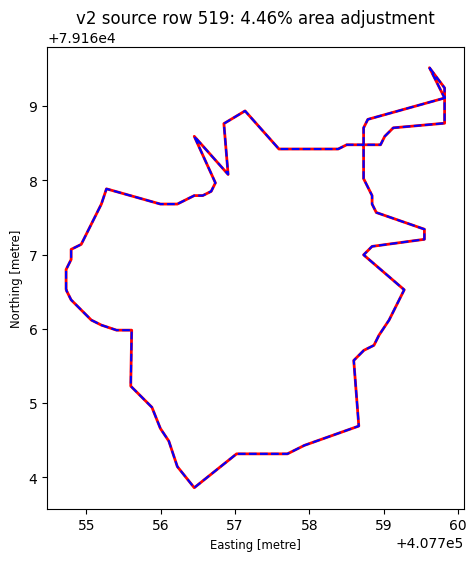

In [2]:
def class_table(g,version):
    out=[]
    for column in [c for c in g.columns if any(k in c.lower() for k in
                  ('class','species','espece','musanga','label'))]:
        counts=g[column].astype('string').fillna('<missing>').value_counts(dropna=False)
        for value,n in counts.items():
            out.append(dict(version=version,field=column,value=str(value),n=int(n)))
    return out
classes=pd.DataFrame(class_table(v1,'v1')+class_table(v2,'v2'),
                     columns=['version','field','value','n'])
display(classes)
classes.to_csv(OUT/'00_annotation_class_fields.csv',index=False)

REPAIRS=[]
REVIEW_GEOMETRIES=[]
def safe_polygon(g,version,row):
    if g is None or g.is_empty:raise ValueError(f'{version} row {row}: empty geometry')
    if g.geom_type in ('Polygon','MultiPolygon') and g.is_valid:return g
    old_area=g.area
    changed=make_valid(g)
    polygons=[]
    def parts(h):
        if h.geom_type=='Polygon':polygons.append(h)
        elif h.geom_type=='MultiPolygon':polygons.extend(list(h.geoms))
        elif hasattr(h,'geoms'):
            for piece in h.geoms:parts(piece)
    parts(changed)
    if not polygons:raise ValueError(f'{version} row {row}: geometry lost polygon')
    revised=unary_union(polygons)
    ratio=abs(revised.area-old_area)/max(old_area,revised.area,1e-12)
    if not revised.is_valid:
        raise ValueError(f'{version} row {row}: make_valid did not produce valid geometry')
    flagged=ratio>0.01
    REPAIRS.append(dict(version=version,source_row=row,
                        original_type=g.geom_type,relative_area_change=ratio,
                        requires_review=flagged))
    if flagged:
        REVIEW_GEOMETRIES.append(dict(version=version,source_row=row,
                                      original_geometry=g,repaired_geometry=revised,
                                      relative_area_change=ratio))
        print(f'⚠️ REVIEW REQUIRED: {version} polygon {row}, '
              f'area changed {ratio:.3%}; provisional geometry used for '
              'diagnostics ONLY. Manifest export will be blocked.',flush=True)
    return revised
v1.geometry=[safe_polygon(g,'v1',i) for i,g in enumerate(v1.geometry)]
v2.geometry=[safe_polygon(g,'v2',i) for i,g in enumerate(v2.geometry)]
repairs=pd.DataFrame(REPAIRS,columns=['version','source_row','original_type',
                                      'relative_area_change','requires_review'])
display(repairs)
repairs.to_csv(OUT/'00_geometry_repairs.csv',index=False)
print('REPAIRED:',len(repairs),'polygons; originals not modified.')

# Save a focused GIS review package with the SOURCE and PROPOSED repair.
# The modified geometry is only used to allow the audit to finish.
if REVIEW_GEOMETRIES:
    review_path=OUT/'00_geometry_review.gpkg'
    if review_path.exists():review_path.unlink()
    rows_source=[dict(version=r['version'],source_row=r['source_row'],
                      area_change_pct=100*r['relative_area_change'],
                      geometry=r['original_geometry']) for r in REVIEW_GEOMETRIES]
    rows_repair=[dict(version=r['version'],source_row=r['source_row'],
                      area_change_pct=100*r['relative_area_change'],
                      geometry=r['repaired_geometry']) for r in REVIEW_GEOMETRIES]
    gpd.GeoDataFrame(rows_source,geometry='geometry',crs=v2.crs).to_file(
        review_path,layer='original_invalid',driver='GPKG')
    gpd.GeoDataFrame(rows_repair,geometry='geometry',crs=v2.crs).to_file(
        review_path,layer='proposed_repair',driver='GPKG')
    print('REVIEW ORIGINAL vs PROPOSED:',review_path)
    import matplotlib.pyplot as plt
    for r in REVIEW_GEOMETRIES[:6]:
        fig,ax=plt.subplots(figsize=(6,6))
        gpd.GeoSeries([r['original_geometry']],crs=v2.crs).boundary.plot(
            ax=ax,color='red',linewidth=2,label='original')
        gpd.GeoSeries([r['repaired_geometry']],crs=v2.crs).boundary.plot(
            ax=ax,color='blue',linestyle='--',linewidth=1.5,label='proposed')
        ax.set_title(f"{r['version']} source row {r['source_row']}: "
                     f"{100*r['relative_area_change']:.2f}% area adjustment")
        ax.set_aspect('equal');plt.show()


## 03 — Circle-cover comparison using spatial intersection (not polygon ownership)

Crowns may cross circle boundaries. The audit includes the clipped intersection of **every** overlapping polygon in each circle, irrespective of its primary circle. Primary membership is only a diagnostic. No >50% polygon-in-circle threshold applies.


In [3]:
METRIC_CRS=circles.crs if circles.crs.is_projected else circles.estimate_utm_crs()
assert METRIC_CRS is not None
v1m=v1.to_crs(METRIC_CRS).copy()
v2m=v2.to_crs(METRIC_CRS).copy()
cm=circles.to_crs(METRIC_CRS).copy()
circle_geom=list(cm.geometry)

# Crowns may span multiple circle boundaries. Do NOT use a majority-area
# membership requirement; assign a dominant circle only for diagnostics.
def describe_membership(gdf,version):
    sidx=cm.sindex
    primary=[];fractions=[];crossings=[];no_hit=[]
    records=[]
    for i,g in enumerate(gdf.geometry):
        candidates=sidx.query(g,predicate='intersects')
        hits=[(int(j),g.intersection(circle_geom[int(j)]).area)
              for j in candidates]
        hits=[(cid,area) for cid,area in hits if area>0]
        if not hits:
            primary.append(-1);fractions.append(0.);crossings.append(0)
            no_hit.append(i)
            records.append(dict(version=version,source_row=i,
                primary_circle_id=-1,fraction_in_primary=0.,
                n_intersected_circles=0))
            continue
        cid,largest=max(hits,key=lambda x:x[1])
        frac=largest/max(g.area,1e-9)
        primary.append(cid);fractions.append(frac);crossings.append(len(hits))
        records.append(dict(version=version,source_row=i,
            primary_circle_id=cid,fraction_in_primary=frac,
            n_intersected_circles=len(hits)))
    gdf['circle_id']=primary
    gdf['fraction_inside']=fractions
    gdf['n_intersected_circles']=crossings
    print(version,':',len(gdf),'source polygons;',
          sum(np.asarray(fractions)<0.5),'with <50% in their primary circle;',
          sum(np.asarray(crossings)>1),'cross more than one circle;',
          len(no_hit),'outside all circle boundaries.')
    if no_hit:
        print('SOURCE POLYGONS NOT INTERSECTING ANY CIRCLE:',no_hit[:30])
    return gdf,pd.DataFrame(records),no_hit

v1m,members1,missing1=describe_membership(v1m,'v1')
v2m,members2,missing2=describe_membership(v2m,'v2')
pd.concat([members1,members2],ignore_index=True).to_csv(
    OUT/'00_polygon_circle_membership_diagnostic.csv',index=False)

def clipped_geometries(gdf,circle):
    # Crucial: EVERY polygon that touches the circle contributes its clipped area,
    # regardless of which circle has the largest intersection.
    ids=gdf.sindex.query(circle,predicate='intersects')
    return [inter for j in ids
            if not (inter:=gdf.geometry.iloc[int(j)].intersection(circle)).is_empty
            and inter.area>0]

area_rows=[]
for version,gdf in [('v1',v1m),('v2',v2m)]:
    for cid,circle in enumerate(circle_geom):
        clipped=clipped_geometries(gdf,circle)
        combined=unary_union(clipped) if clipped else Polygon()
        raw_area=sum(g.area for g in clipped)
        covered_area=combined.area
        area_rows.append(dict(version=version,circle_id=cid,
            circle_area_m2=circle.area,polygons=len(clipped),
            summed_annotation_area_m2=raw_area,
            musanga_union_area_m2=covered_area,
            musanga_cover_pct=100*covered_area/max(circle.area,1e-9),
            overlapping_annotation_area_m2=max(0,raw_area-covered_area),
            # Number of intersecting polygons also crossing the boundary.
            outside_circle_polygons=sum(
                1 for g in clipped if g.area>0) if False else
                sum(1 for j in gdf.sindex.query(circle,predicate='intersects')
                    if not circle.covers(gdf.geometry.iloc[int(j)]))))
area=pd.DataFrame(area_rows)
wide=area.pivot(index='circle_id',columns='version')
comparison=pd.DataFrame({'circle_id':range(len(circle_geom))})
for col in ['polygons','musanga_cover_pct','musanga_union_area_m2',
            'overlapping_annotation_area_m2','outside_circle_polygons']:
    for version in ['v1','v2']:
        comparison[col+'_'+version]=wide[col][version].to_numpy()
comparison['delta_polygons']=comparison.polygons_v2-comparison.polygons_v1
comparison['delta_cover_pp']=comparison.musanga_cover_pct_v2-comparison.musanga_cover_pct_v1
comparison['abs_delta_cover_pp']=comparison.delta_cover_pp.abs()
comparison['delta_union_area_m2']=comparison.musanga_union_area_m2_v2-comparison.musanga_union_area_m2_v1
comparison.to_csv(OUT/'00_circle_v1_v2_comparison.csv',index=False)
area.to_csv(OUT/'00_circle_reference_metrics_long.csv',index=False)
display(comparison.round(3))
print('Change in source polygon count:',len(v2)-len(v1))
print('Mean absolute circle cover change (pp):',
      round(comparison.abs_delta_cover_pp.mean(),3))
print('Largest changes:')
display(comparison.nlargest(10,'abs_delta_cover_pp')[
    ['circle_id','polygons_v1','polygons_v2',
     'musanga_cover_pct_v1','musanga_cover_pct_v2','delta_cover_pp']].round(3))


v1 : 1394 source polygons; 83 with <50% in their primary circle; 0 cross more than one circle; 5 outside all circle boundaries.
SOURCE POLYGONS NOT INTERSECTING ANY CIRCLE: [406, 407, 408, 1072, 1219]
v2 : 605 source polygons; 43 with <50% in their primary circle; 0 cross more than one circle; 6 outside all circle boundaries.
SOURCE POLYGONS NOT INTERSECTING ANY CIRCLE: [115, 225, 254, 273, 585, 586]


,circle_id,polygons_v1,polygons_v2,musanga_cover_pct_v1,musanga_cover_pct_v2,musanga_union_area_m2_v1,musanga_union_area_m2_v2,overlapping_annotation_area_m2_v1,overlapping_annotation_area_m2_v2,outside_circle_polygons_v1,outside_circle_polygons_v2,delta_polygons,delta_cover_pp,abs_delta_cover_pp,delta_union_area_m2
0,0,26,18,71.102,45.227,8699.738,5533.861,2.124,1.328,13,5,-8,-25.874,25.874,-3165.877
1,1,36,33,28.166,19.843,3446.363,2427.922,0.062,1.111,13,11,-3,-8.324,8.324,-1018.442
2,2,39,50,41.844,26.759,5120.294,3274.331,2.177,0.732,10,11,11,-15.086,15.086,-1845.963
3,3,29,12,43.368,54.938,5311.724,6728.910,2.860,11.178,4,6,-17,11.571,11.571,1417.186
4,4,10,6,9.970,4.238,1221.205,519.072,0.020,0.000,6,3,-4,-5.732,5.732,-702.133
5,5,8,12,72.169,38.362,8838.869,4698.424,2.483,1.472,6,2,4,-33.806,33.806,-4140.444
6,6,6,23,43.859,20.529,5371.735,2514.303,0.068,0.092,4,3,17,-23.330,23.330,-2857.432
7,7,5,28,77.416,45.731,9482.099,5601.196,6.235,2.977,5,5,23,-31.686,31.686,-3880.903
8,8,24,14,40.299,9.343,4935.941,1144.307,2.758,1.024,9,2,-10,-30.956,30.956,-3791.634
9,9,16,9,13.544,5.062,1658.793,619.937,0.000,0.067,4,1,-7,-8.482,8.482,-1038.856


Change in source polygon count: -789
Mean absolute circle cover change (pp): 19.527
Largest changes:


,circle_id,polygons_v1,polygons_v2,musanga_cover_pct_v1,musanga_cover_pct_v2,delta_cover_pp
24,24,10,15,85.439,8.957,-76.481
27,27,30,17,68.970,17.231,-51.740
23,23,30,30,58.246,14.850,-43.396
10,10,108,15,40.348,1.925,-38.423
5,5,8,12,72.169,38.362,-33.806
7,7,5,28,77.416,45.731,-31.686
8,8,24,14,40.299,9.343,-30.956
29,29,56,6,29.296,2.185,-27.111
0,0,26,18,71.102,45.227,-25.874
32,32,38,37,42.109,18.694,-23.415


## 04 — Shape changes, overlaps, and class/coverage gates

This block compares *unions* within each circle; the union IoU quantifies agreement between versions, and added/removed area identifies the direction of changes. Checks for duplicated polygon geometries in v2 are separate.

**Do not assume row indices represent matched polygons across versions.** Use spatial overlay instead.


In [4]:
shape_rows=[];duplicates=[]
for cid,circle in enumerate(circle_geom):
    a=clipped_geometries(v1m,circle)
    b=clipped_geometries(v2m,circle)
    ua=unary_union(a) if a else Polygon()
    ub=unary_union(b) if b else Polygon()
    intersect=ua.intersection(ub).area
    union=ua.union(ub).area
    shape_rows.append(dict(circle_id=cid,
        union_IoU_v1_v2=intersect/union if union else 1.,
        added_m2=max(0,ub.area-intersect),
        removed_m2=max(0,ua.area-intersect),
        symmetric_difference_m2=ua.symmetric_difference(ub).area))
    group=v2m.iloc[v2m.sindex.query(circle,predicate='intersects')]
    items=list(zip(group.source_row,group.geometry))
    for j,(row1,g1) in enumerate(items):
        for row2,g2 in items[j+1:]:
            if not g1.intersects(g2):continue
            overlap=g1.intersection(g2).area
            iou=overlap/max(g1.area+g2.area-overlap,1e-9)
            if iou>=0.9999:
                duplicates.append(dict(circle_id=cid,source_row_1=int(row1),
                                       source_row_2=int(row2),iou=iou))
shape=pd.DataFrame(shape_rows)
duplicates=pd.DataFrame(duplicates,columns=['circle_id','source_row_1','source_row_2','iou'])
shape.to_csv(OUT/'00_circle_union_shape_change.csv',index=False)
duplicates.to_csv(OUT/'00_v2_duplicate_polygons.csv',index=False)
display(shape.round(3))
print('EXACT v2 DUPLICATES:',len(duplicates))
display(duplicates)

# Preserve both source and geometry sanity checks in the manifest.
assert len(circle_geom)==34, 'Circle reference registry changed unexpectedly'
# Zero-Musanga circles are valid reference negatives; report rather than reject.
empty_v2=comparison.loc[comparison.polygons_v2==0,'circle_id'].astype(int).tolist()
if empty_v2:
    print('ZERO-POLYGON CIRCLES IN V2 (review against source):',empty_v2)
assert not (comparison.musanga_cover_pct_v2>100.001).any()
assert len(duplicates)==0, 'V2 contains exact duplicate polygons: inspect before approval.'
print('GEOMETRY and CIRCLE-COVERAGE QA PASSED.')


,circle_id,union_IoU_v1_v2,added_m2,removed_m2,symmetric_difference_m2
0,0,0.615,111.953,3277.830,3389.783
1,1,0.655,102.634,1121.076,1223.710
2,2,0.604,114.525,1960.488,2075.012
3,3,0.706,1747.951,330.765,2078.716
4,4,0.424,0.524,702.657,703.181
5,5,0.531,1.990,4142.434,4144.424
6,6,0.453,55.383,2912.815,2968.198
7,7,0.578,75.292,3956.195,4031.487
8,8,0.229,10.318,3801.952,3812.271
9,9,0.370,4.098,1042.954,1047.051


EXACT v2 DUPLICATES: 0


,circle_id,source_row_1,source_row_2,iou


GEOMETRY and CIRCLE-COVERAGE QA PASSED.


## 05 — Approve and save immutable V3_1 manifest

This does **not** mutate the V3 manifest or source shapefiles. A compatible-looking copy of the original input registry is stored under `Outputs/V3_1`, with explicit `schema_version`, source fingerprints and `reference_version`.

**Critical:** inspect class distributions. If v2 now distinguishes negative from positive crown annotations rather than remaining an all-Musanga polygon layer, set `APPROVE_ALL_V2_POLYGONS_AS_MUSANGA=False` and **do not proceed** until the reference-label generator is revised.

**Polygons outside all exhaustive circles:** They are listed in `00_v2_outside_circle_rows.json`, retained in the source, but contribute no area to circle statistics. They do not prevent exploratory manifest creation.


In [6]:
APPROVE_ALL_V2_POLYGONS_AS_MUSANGA=True   # Manually set True ONLY after checking v2 attributes
ACCEPT_PROVISIONAL_REPAIRS={519}  # v2 row 519 only; 4.465% area change, exploratory rerun
WRITE_V3_1_MANIFEST=True                   # Set True after reviewing Sections 02–04

def sha256_file(path,buffer=1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        while True:
            chunk=handle.read(buffer)
            if not chunk:break
            h.update(chunk)
    return h.hexdigest()
def shapefile_fingerprint(shp):
    parts={}
    for suffix in ('.shp','.shx','.dbf','.prj','.cpg'):
        part=shp.with_suffix(suffix)
        if part.exists():parts[part.name]={'bytes':part.stat().st_size,
                                           'sha256':sha256_file(part)}
    assert all(shp.with_suffix(s).exists() for s in ('.shp','.shx','.dbf','.prj'))
    return parts

if WRITE_V3_1_MANIFEST:
    assert APPROVE_ALL_V2_POLYGONS_AS_MUSANGA, (
        'Explicit approval of all-v2-annotations-as-Musanga is required. '
        'If labels contain negatives, revise the reference contract first.')
    flagged={(r['version'],int(r['source_row'])) for r in REPAIRS
             if r['requires_review']}
    allowed={('v2',int(j)) for j in ACCEPT_PROVISIONAL_REPAIRS}
    assert flagged.issubset(allowed), (
        f'Unapproved >1% repairs: {sorted(flagged-allowed)}. '
        'Only explicitly listed repairs can be used in this exploratory rerun.')
    print('PROVISIONAL GEOMETRY REPAIRS APPROVED:',sorted(flagged))
    assert all(0<=j<len(v2) for j in ACCEPT_PROVISIONAL_REPAIRS)
    # Crown polygons outside the 34 audited circles have no bearing on
    # exhaustive-circle reference labels. Preserve and report them; never
    # force them into the nearest circle or treat their areas as negatives.
    outside_v2=list(map(int,missing2))
    print('V2 polygons outside all 34 circles (excluded from circle metrics):',
          outside_v2)
    (OUT/'00_v2_outside_circle_rows.json').write_text(json.dumps({
        'n_outside':len(outside_v2),'source_rows':outside_v2,
        'policy':'retain source polygons; ignore in exhaustive-circle labels'
    },indent=2))
    assert len(duplicates)==0
    assert len(circle_geom)==34, 'Circle boundaries are required for exhaustive negative areas'

    registry=json.loads(json.dumps(base))  # Copy for preservation; original remains unchanged.
    registry['schema_version']='v3_1_input_audit_nadine_v2'
    registry['parent_schema_version']=base['schema_version']
    registry['reference_version']='Nadine_v2'
    registry['exhaustive_annotations']['positive_polygons']=str(V2)
    registry['exhaustive_annotations']['musanga_polygons']=int(len(v2))
    registry['exhaustive_annotations']['all_annotation_polygons_musanga']=True
    registry['exhaustive_annotations']['verified_exhaustive_circle_count']=34
    registry['exhaustive_annotations']['verified_exhaustive_circle_rows']=list(range(34))
    registry['annotation_versioning']={
        'baseline_manifest':str(V3_MANIFEST),
        'baseline_annotations':str(V1),
        'new_annotations':str(V2),
        'v1_sha256':shapefile_fingerprint(V1),
        'v2_sha256':shapefile_fingerprint(V2),
        'v1_feature_count':int(len(v1)),
        'v2_feature_count':int(len(v2)),
        'v2_polygon_rows_outside_all_circles':outside_v2,
        'outside_circle_policy':'source polygons retained; only clipped intersections contribute to exhaustive circle reference',
        'v2_geometry_repairs':int((repairs.version=='v2').sum()),
        'provisionally_accepted_geometry_repairs':[
            {'version':v,'source_row':row,
             'relative_area_change':next(r['relative_area_change'] for r in REPAIRS
                 if r['version']==v and r['source_row']==row)}
            for v,row in sorted(flagged)],
        'interpretation':'exploratory exhaustive positive reference; v2 may be over-strict',
        'audit_circle_comparison':str(OUT/'00_circle_v1_v2_comparison.csv'),
        'audit_union_geometry':str(OUT/'00_circle_union_shape_change.csv'),
        'audit_class_fields':str(OUT/'00_annotation_class_fields.csv')
    }
    destination=OUT/'00_input_manifest.json'
    if destination.exists():
        old=json.loads(destination.read_text())
        assert old.get('annotation_versioning',{}).get('v2_sha256')==registry['annotation_versioning']['v2_sha256'], (
            'Source v2 changed after a prior audit! Review version history before overwriting.')
    destination.write_text(json.dumps(registry,indent=2))
    print('APPROVED V3_1 MANIFEST:',destination)
    print('V3 manifest unchanged:',V3_MANIFEST)
    print('IMPORTANT: Next update V3_1 NB01, not V3 NB01.')
else:
    print('Audit only. Review classes/geometries, then explicitly approve and enable manifest export.')


PROVISIONAL GEOMETRY REPAIRS APPROVED: [('v2', 519)]
V2 polygons outside all 34 circles (excluded from circle metrics): [115, 225, 254, 273, 585, 586]
APPROVED V3_1 MANIFEST: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/00_input_audit/00_input_manifest.json
V3 manifest unchanged: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/00_input_audit/00_input_manifest.json
IMPORTANT: Next update V3_1 NB01, not V3 NB01.
